## Task 1 — Data acquisition and exploration

The assignment describes the URFD dataset as approximately 4 GB, with 70 sequences (30 falls and 40 ADL), RGB and depth modalities, and accelerometer streams. This notebook uses RGB video files for the baseline classifier.

Download the dataset from the Kaggle page specified in the assignment, extract it, and set `DATASET_DIR` below. If Kaggle API credentials are configured, you may alternatively download it with the Kaggle CLI from a terminal:
`kaggle datasets download -d shahliza27/ur-fall-detection-dataset --unzip -p ./urfd_dataset`

**Visual distinction:** fall clips generally contain a rapid descent to the floor and a lying/resting posture; ADL clips show ordinary activities such as walking, sitting, or standing. Labels are inferred from folder/file names, so inspect the printed label summary and correct the mapping if your extracted layout uses different names.

In [2]:

%pip install -q opencv-python-headless scikit-learn matplotlib pandas tensorflow


In [4]:
%pip install -q kaggle

In [5]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.set_config_value("username", input("Enter your Kaggle username: "))
api.set_config_value("key", getpass("Enter your Kaggle API key: "))
api.authenticate()

print("Kaggle connected successfully!")

Enter your Kaggle username: praveenkumar790
- username is now set to: praveenkumar790
Enter your Kaggle API key: ··········
- key is now set to: KGAT_f8703d166a1b741191ea64a70db1e898
Kaggle connected successfully!


In [6]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass(
    "Paste your Kaggle API token here: "
)

print("Token is ready for this Colab session!")

Paste your Kaggle API token here: ··········
Token is ready for this Colab session!


In [7]:
!kaggle datasets download -d shahliza27/ur-fall-detection-dataset -p /content/urfd_dataset --unzip

Dataset URL: https://www.kaggle.com/datasets/shahliza27/ur-fall-detection-dataset
License(s): unknown
100% 4.18G/4.18G [00:35<00:00, 126MB/s]



In [8]:
import os

dataset_path = "/content/urfd_dataset"

for root, dirs, files in os.walk(dataset_path):
    print("Folder:", root)
    print("Subfolders:", dirs[:5])
    print("Files:", files[:5])
    print("-" * 40)

    # Show only the first few folders
    if root.count(os.sep) >= 4:
        dirs.clear()

Folder: /content/urfd_dataset
Subfolders: ['UR_fall_detection_dataset_cam0_rgb']
Files: []
----------------------------------------
Folder: /content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb
Subfolders: ['adl-16-cam0-rgb', 'fall-06-cam0-rgb', 'adl-18-cam0-rgb', 'adl-06-cam0-rgb', 'adl-12-cam0-rgb']
Files: []
----------------------------------------
Folder: /content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb/adl-16-cam0-rgb
Subfolders: []
Files: ['adl-16-cam0-rgb-079.png', 'adl-16-cam0-rgb-036.png', 'adl-16-cam0-rgb-068.png', 'adl-16-cam0-rgb-106.png', 'adl-16-cam0-rgb-091.png']
----------------------------------------
Folder: /content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb/fall-06-cam0-rgb
Subfolders: []
Files: ['fall-06-cam0-rgb-033.png', 'fall-06-cam0-rgb-015.png', 'fall-06-cam0-rgb-077.png', 'fall-06-cam0-rgb-031.png', 'fall-06-cam0-rgb-050.png']
----------------------------------------
Folder: /content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb/adl-18-cam0-

In [9]:
import os

dataset_path = "/content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb"

folders = [
    name for name in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, name))
]

fall_folders = [name for name in folders if name.startswith("fall-")]
adl_folders = [name for name in folders if name.startswith("adl-")]

print("Total activity folders:", len(folders))
print("Fall folders:", len(fall_folders))
print("Normal activity (ADL) folders:", len(adl_folders))

Total activity folders: 70
Fall folders: 30
Normal activity (ADL) folders: 40


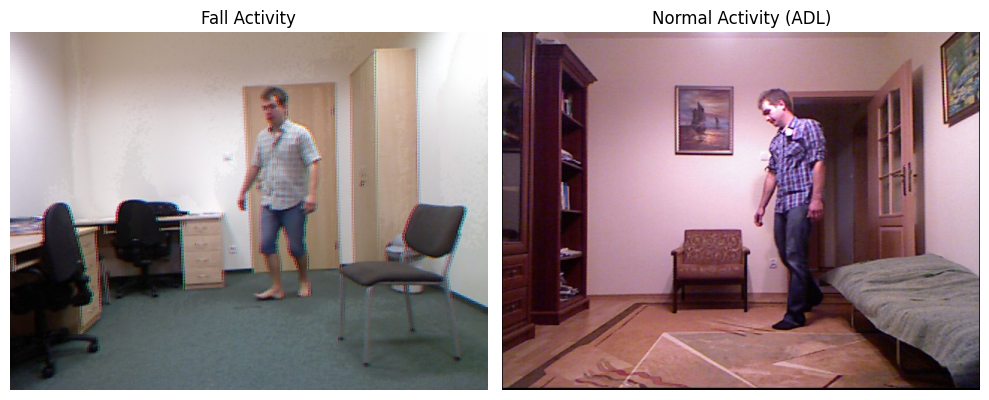

In [10]:
import os
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb"

# Select one fall sequence and one normal activity sequence
fall_folder = os.path.join(dataset_path, "fall-01-cam0-rgb")
adl_folder = os.path.join(dataset_path, "adl-01-cam0-rgb")

# Display one image from each sequence
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, folder, title in zip(
    axes,
    [fall_folder, adl_folder],
    ["Fall Activity", "Normal Activity (ADL)"]
):
    images = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith(".png")
    ])

    img = Image.open(os.path.join(folder, images[len(images)//2]))
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:

import os
import numpy as np
from PIL import Image

# Dataset folder
dataset_path = "/content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb"

# Settings for our 3D CNN
NUM_FRAMES = 16
IMG_SIZE = 112

def load_sequence(folder_path):
    # Get all image frames in the folder
    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(".png")
    ])

    # Select 16 frames evenly across the sequence
    if len(image_files) < NUM_FRAMES:
        return None

    indices = np.linspace(
        0, len(image_files) - 1, NUM_FRAMES, dtype=int
    )

    frames = []

    for idx in indices:
        image_path = os.path.join(folder_path, image_files[idx])

        # Load image as RGB and resize it
        img = Image.open(image_path).convert("RGB")
        img = img.resize((IMG_SIZE, IMG_SIZE))

        # Convert image to numbers between 0 and 1
        img_array = np.array(img, dtype=np.float32) / 255.0
        frames.append(img_array)

    # Combine all 16 frames into one sequence
    return np.stack(frames, axis=0)

# Test on one fall sequence
test_folder = os.path.join(
    dataset_path, "fall-01-cam0-rgb"
)

sample_sequence = load_sequence(test_folder)

if sample_sequence is not None:
    print("Sequence created successfully!")
    print("Sequence shape:", sample_sequence.shape)
else:
    print("Not enough frames in this folder.")


Sequence created successfully!
Sequence shape: (16, 112, 112, 3)


In [12]:

import os
import numpy as np
from PIL import Image

dataset_path = "/content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb"

NUM_FRAMES = 16
IMG_SIZE = 112

X = []
y = []
sequence_names = []

# Go through all activity folders
for folder_name in sorted(os.listdir(dataset_path)):
    folder_path = os.path.join(dataset_path, folder_name)

    if not os.path.isdir(folder_path):
        continue

    # Assign labels: fall = 1, normal ADL = 0
    if folder_name.lower().startswith("fall-"):
        label = 1
    elif folder_name.lower().startswith("adl-"):
        label = 0
    else:
        continue

    # Read image frames from this activity
    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(".png")
    ])

    # Skip folders with fewer than 16 frames
    if len(image_files) < NUM_FRAMES:
        print("Skipped:", folder_name)
        continue

    # Select 16 frames evenly across the activity
    indices = np.linspace(
        0, len(image_files) - 1, NUM_FRAMES, dtype=int
    )

    frames = []

    try:
        for idx in indices:
            image_path = os.path.join(folder_path, image_files[idx])

            img = Image.open(image_path).convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE))

            frame_array = np.array(img, dtype=np.float32) / 255.0
            frames.append(frame_array)

        X.append(np.stack(frames, axis=0))
        y.append(label)
        sequence_names.append(folder_name)

    except Exception as e:
        print("Skipped damaged sequence:", folder_name, e)

# Convert lists into NumPy arrays
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("\nDataset preparation complete!")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Fall sequences:", int(np.sum(y == 1)))
print("Normal sequences:", int(np.sum(y == 0)))
print("Total sequences:", len(y))



Dataset preparation complete!
X shape: (70, 16, 112, 112, 3)
y shape: (70,)
Fall sequences: 30
Normal sequences: 40
Total sequences: 70


In [13]:

from sklearn.model_selection import train_test_split
import numpy as np

# First: separate 70% training data from 30% remaining data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second: divide the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training sequences:", len(X_train))
print("Validation sequences:", len(X_val))
print("Testing sequences:", len(X_test))

print("\nTraining labels - Fall:", int(np.sum(y_train == 1)),
      "| Normal:", int(np.sum(y_train == 0)))

print("Validation labels - Fall:", int(np.sum(y_val == 1)),
      "| Normal:", int(np.sum(y_val == 0)))

print("Testing labels - Fall:", int(np.sum(y_test == 1)),
      "| Normal:", int(np.sum(y_test == 0)))


Training sequences: 49
Validation sequences: 10
Testing sequences: 11

Training labels - Fall: 21 | Normal: 28
Validation labels - Fall: 4 | Normal: 6
Testing labels - Fall: 5 | Normal: 6


In [14]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Build the 3D CNN model
model = models.Sequential([
    layers.Input(shape=(16, 112, 112, 3)),

    # First 3D convolution layer
    layers.Conv3D(
        16, kernel_size=(3, 3, 3),
        activation="relu", padding="same"
    ),
    layers.MaxPooling3D(pool_size=(1, 2, 2)),

    # Second 3D convolution layer
    layers.Conv3D(
        32, kernel_size=(3, 3, 3),
        activation="relu", padding="same"
    ),
    layers.MaxPooling3D(pool_size=(2, 2, 2)),

    # Third 3D convolution layer
    layers.Conv3D(
        64, kernel_size=(3, 3, 3),
        activation="relu", padding="same"
    ),
    layers.MaxPooling3D(pool_size=(2, 2, 2)),

    # Convert feature maps into a single vector
    layers.GlobalAveragePooling3D(),

    # Reduce overfitting
    layers.Dropout(0.3),

    # Binary classification: fall or normal
    layers.Dense(1, activation="sigmoid")
])

# Configure model training
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model structure
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70,593 (275.75 KB)

 Trainable params: 70,593 (275.75 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:

# Train the model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=4,
    verbose=1
)

print("\nModel training completed!")


Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 21s 751ms/step - accuracy: 0.5510 - loss: 0.7011 - val_accuracy: 0.6000 - val_loss: 0.6843
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.5714 - loss: 0.7392 - val_accuracy: 0.6000 - val_loss: 0.6685
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.5714 - loss: 0.6768 - val_accuracy: 0.6000 - val_loss: 0.6750
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.5714 - loss: 0.6921 - val_accuracy: 0.6000 - val_loss: 0.6691
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.5510 - loss: 0.6878 - val_accuracy: 0.6000 - val_loss: 0.6247
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.5510 - loss: 0.6403 - val_accuracy: 0.5000 - val_loss: 0.5908
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.7143 - loss: 0.6140 - val_accuracy: 0.5000 - val_loss: 0.4860
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.5714 - loss: 0.5616 - val_accuracy: 0.7000 -

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Accuracy: 0.7273
Precision: 0.625
Recall: 1.0
F1 Score: 0.7692
AUROC: 0.7667


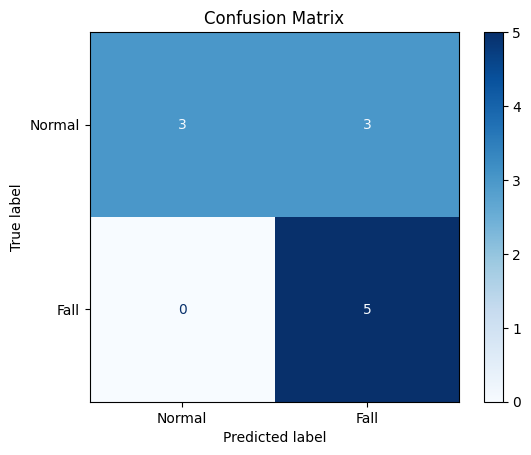

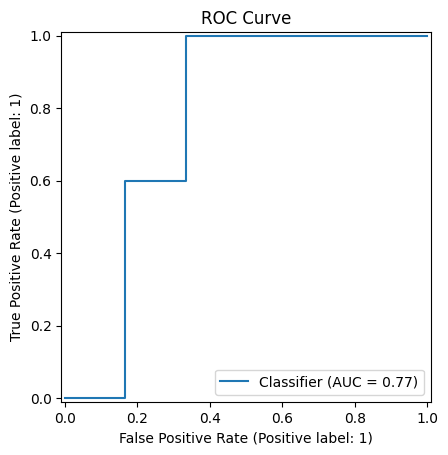


Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.50      0.67         6
        Fall       0.62      1.00      0.77         5

    accuracy                           0.73        11
   macro avg       0.81      0.75      0.72        11
weighted avg       0.83      0.73      0.71        11



In [16]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Predict fall probabilities on the test data
y_prob = model.predict(X_test).ravel()

# Convert probabilities to class labels
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

# AUROC requires both classes to be present in the test set
if len(np.unique(y_test)) == 2:
    print("AUROC:", round(roc_auc_score(y_test, y_prob), 4))
else:
    print("AUROC cannot be calculated: test set contains only one class.")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fall"]
).plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

# ROC curve
if len(np.unique(y_test)) == 2:
    RocCurveDisplay.from_predictions(y_test, y_prob)
    plt.title("ROC Curve")
    plt.show()

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Fall"],
    zero_division=0
))


In [19]:

from google.colab import files

files.download("/content/fall_detection_3d_cnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

from google.colab import files

files.download("/content/fall_detection_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

import pandas as pd
import numpy as np

# Save the trained 3D CNN model
model.save("/content/fall_detection_3d_cnn.keras")

# Save evaluation metrics
results = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "AUROC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
        if len(np.unique(y_test)) == 2 else np.nan
    ]
}

results_df = pd.DataFrame(results)
results_df.to_csv("/content/fall_detection_results.csv", index=False)

print("Model saved: fall_detection_3d_cnn.keras")
print("Metrics saved: fall_detection_results.csv")
print("\nEvaluation Results:")
print(results_df.to_string(index=False))


Model saved: fall_detection_3d_cnn.keras
Metrics saved: fall_detection_results.csv

Evaluation Results:
   Metric    Score
 Accuracy 0.727273
Precision 0.625000
   Recall 1.000000
 F1 Score 0.769231
    AUROC 0.766667


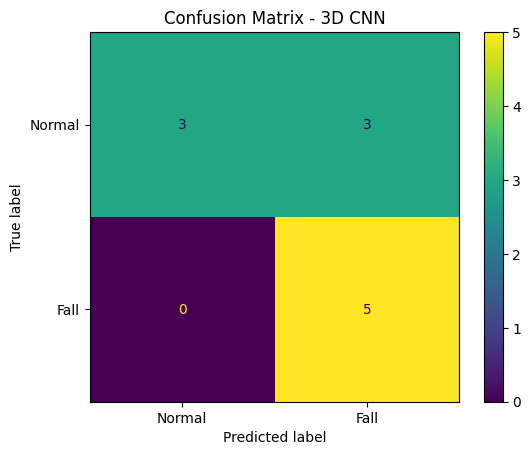

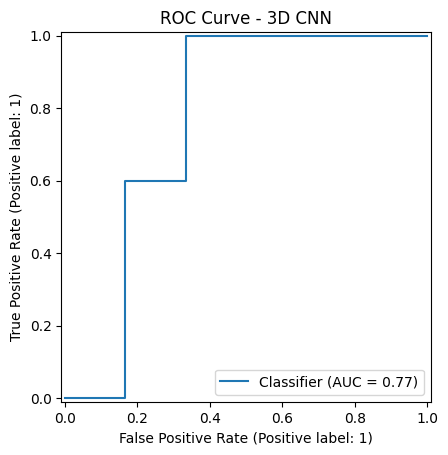

In [18]:

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    confusion_matrix
)
import matplotlib.pyplot as plt

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fall"]
).plot()

plt.title("Confusion Matrix - 3D CNN")
plt.show()

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve - 3D CNN")
plt.show()


In [1]:
# Install these packages in your notebook environment if needed:
# %pip install opencv-python tensorflow scikit-learn matplotlib pandas

import os, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# CHANGE THIS to the directory containing your extracted URFD dataset.
DATASET_DIR = Path("./urfd_dataset")
VIDEO_EXTENSIONS = {".avi", ".mp4", ".mov", ".mkv", ".mpeg", ".mpg"}

print("Dataset directory:", DATASET_DIR.resolve())
print("Directory exists:", DATASET_DIR.exists())

Dataset directory: /content/urfd_dataset
Directory exists: False


In [21]:
# Recursively discover videos. Labels are inferred from path/name tokens.
# Fall tokens are checked first; ADL/normal tokens are checked second.
def infer_label(path):
    text = str(path).lower().replace("-", "_").replace(" ", "_")
    fall_tokens = ("fall", "falls", "fallen")
    adl_tokens = ("adl", "nonfall", "non_fall", "normal", "activity", "activities")

    # Avoid treating 'nonfall' as fall due to substring matching.
    if any(token in text for token in ("nonfall", "non_fall")):
        return 0
    if any(token in text for token in fall_tokens):
        return 1
    if any(token in text for token in adl_tokens):
        return 0
    return None

video_records = []
if DATASET_DIR.exists():
    for p in DATASET_DIR.rglob("*"):
        if p.is_file() and p.suffix.lower() in VIDEO_EXTENSIONS:
            label = infer_label(p.relative_to(DATASET_DIR))
            if label is not None:
                video_records.append({"path": str(p), "label": int(label),
                                      "class_name": "Fall" if label == 1 else "Non-Fall"})
else:
    print("Dataset folder not found. Download/extract the dataset and update DATASET_DIR.")

videos_df = pd.DataFrame(video_records)
print("Recognized video files:", len(videos_df))
if not videos_df.empty:
    print(videos_df["class_name"].value_counts())
    display(videos_df.head(10))
else:
    print("No labelled videos detected. Inspect folder/file names and update infer_label() if needed.")

Recognized video files: 0
No labelled videos detected. Inspect folder/file names and update infer_label() if needed.


### Data validation
The next cell checks whether videos can be opened and have readable frames. Unreadable files are excluded. For a small dataset, this may take a little time.

In [22]:
def video_is_readable(path):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        cap.release()
        return False
    ok, frame = cap.read()
    cap.release()
    return bool(ok and frame is not None and frame.size > 0)

if not videos_df.empty:
    videos_df["readable"] = videos_df["path"].apply(video_is_readable)
    print("Readable videos:", int(videos_df["readable"].sum()), "/", len(videos_df))
    print("Excluded unreadable videos:", int((~videos_df["readable"]).sum()))
    videos_df = videos_df[videos_df["readable"]].drop(columns="readable").reset_index(drop=True)
    print("Usable class counts:")
    display(videos_df["class_name"].value_counts().rename_axis("class").to_frame("videos"))

In [23]:
# Preview a sample video from each class.
def read_preview_frames(video_path, n_frames=4):
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        return []
    indices = np.linspace(0, max(total - 1, 0), n_frames, dtype=int)
    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()
        if ok and frame is not None:
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()
    return frames

if not videos_df.empty:
    for label, title in [(0, "Non-Fall / ADL"), (1, "Fall")]:
        subset = videos_df[videos_df.label == label]
        if len(subset):
            sample_path = subset.iloc[0]["path"]
            frames = read_preview_frames(sample_path)
            if frames:
                fig, axes = plt.subplots(1, len(frames), figsize=(12, 3))
                if len(frames) == 1: axes = [axes]
                for ax, frame in zip(axes, frames):
                    ax.imshow(frame); ax.axis("off")
                fig.suptitle(f"{title}: {Path(sample_path).name}")
                plt.tight_layout(); plt.show()
            else:
                print("Could not preview:", sample_path)
        else:
            print("No videos detected for class:", title)

## Task 2 — Preprocessing

Each video is sampled uniformly into a fixed-length clip. Frames are resized to 112 × 112, converted to RGB, and normalized to `[0, 1]`. A clip tensor has shape `(frames, height, width, channels)`; a batch has shape `(batch, frames, height, width, channels)`.

In [24]:
NUM_FRAMES = 16
IMG_HEIGHT = 112
IMG_WIDTH = 112
CHANNELS = 3
BATCH_SIZE = 2  # Small batch is safer on limited RAM/GPUs.

def load_video(path, num_frames=NUM_FRAMES, height=IMG_HEIGHT, width=IMG_WIDTH):
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = []
    if total > 0:
        indices = np.linspace(0, total - 1, num_frames, dtype=int)
        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, frame = cap.read()
            if ok and frame is not None:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frame = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)
                frames.append(frame)
    cap.release()

    # If some frames fail to decode, repeat the last valid frame; if all fail, reject.
    if not frames:
        raise ValueError(f"No frames could be decoded from: {path}")
    while len(frames) < num_frames:
        frames.append(frames[-1].copy())
    frames = frames[:num_frames]
    return np.asarray(frames, dtype=np.float32) / 255.0

if not videos_df.empty:
    sample = load_video(videos_df.iloc[0]["path"])
    print("Single clip shape:", sample.shape)
    print("Pixel range:", float(sample.min()), "to", float(sample.max()))

### Train/validation/test split and class imbalance
Split by **video**, using stratification where possible: 70% training, 15% validation, and 15% testing. Because the dataset is small, exact ratios may vary by one video. The training loss uses class weights to reduce the effect of imbalance. Augmentation is applied only to training clips.

In [31]:
import os

DATASET_DIR = "/content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb"

print("Dataset folder exists:", os.path.exists(DATASET_DIR))

if os.path.exists(DATASET_DIR):
    folders = [
        name for name in os.listdir(DATASET_DIR)
        if os.path.isdir(os.path.join(DATASET_DIR, name))
    ]

    print("Activity folders found:", len(folders))
    print("Example folders:", sorted(folders)[:5])

Dataset folder exists: True
Activity folders found: 70
Example folders: ['adl-01-cam0-rgb', 'adl-02-cam0-rgb', 'adl-03-cam0-rgb', 'adl-04-cam0-rgb', 'adl-05-cam0-rgb']


In [32]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

DATASET_DIR = "/content/urfd_dataset/UR_fall_detection_dataset_cam0_rgb"
SEED = 42

# Create one record for each activity folder
records = []

for folder_name in sorted(os.listdir(DATASET_DIR)):
    folder_path = os.path.join(DATASET_DIR, folder_name)

    if not os.path.isdir(folder_path):
        continue

    name = folder_name.lower()

    if name.startswith("fall-"):
        label = 1  # Fall
    elif name.startswith("adl-"):
        label = 0  # Normal activity
    else:
        continue

    records.append({
        "path": folder_path,
        "label": label,
        "name": folder_name
    })

videos_df = pd.DataFrame(records)

print("Total sequences:", len(videos_df))
print("Class counts:")
print(videos_df["label"].map({0: "Normal", 1: "Fall"}).value_counts())

# Split 70% training, 15% validation, 15% testing
train_df, temp_df = train_test_split(
    videos_df,
    test_size=0.30,
    random_state=SEED,
    stratify=videos_df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# Calculate class weights using the training labels
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].to_numpy()
)

CLASS_WEIGHTS = {
    int(c): float(w) for c, w in zip(classes, weights)
}

print("Class weights:", CLASS_WEIGHTS)


Total sequences: 70
Class counts:
label
Normal    40
Fall      30
Name: count, dtype: int64

Train: 49
Validation: 10
Test: 11
Class weights: {0: 0.875, 1: 1.1666666666666667}


In [37]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

if videos_df.empty:
    raise RuntimeError(
        "No labelled videos were found. Set DATASET_DIR correctly and ensure folder/file names "
        "contain recognizable labels (fall, ADL, normal, nonfall)."
    )

if videos_df["label"].nunique() < 2:
    raise RuntimeError("Both classes (Fall and Non-Fall/ADL) must be present for binary classification.")

# First split: 70% train, 30% temporary; then split temporary equally.
train_df, temp_df = train_test_split(
    videos_df, test_size=0.30, random_state=SEED, stratify=videos_df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
)

for split_name, split_df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{split_name}: {len(split_df)} videos")
    print(split_df["label"].map({0:"Non-Fall", 1:"Fall"}).value_counts().to_dict())

classes = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=train_df["label"].to_numpy())
CLASS_WEIGHTS = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", CLASS_WEIGHTS)

Train: 49 videos
{'Non-Fall': 28, 'Fall': 21}
Validation: 10 videos
{'Non-Fall': 6, 'Fall': 4}
Test: 11 videos
{'Non-Fall': 6, 'Fall': 5}
Class weights: {0: 0.875, 1: 1.1666666666666667}


In [33]:

import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
import warnings

# Settings
NUM_FRAMES = 16
IMG_HEIGHT = 112
IMG_WIDTH = 112
CHANNELS = 3
BATCH_SIZE = 4

def load_video(folder_path):
    """Load 16 evenly spaced PNG frames from one activity folder."""
    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(".png")
    ])

    if len(image_files) < NUM_FRAMES:
        raise ValueError("Not enough PNG frames in " + folder_path)

    indices = np.linspace(
        0, len(image_files) - 1, NUM_FRAMES, dtype=int
    )

    frames = []

    for idx in indices:
        image_path = os.path.join(folder_path, image_files[idx])

        with Image.open(image_path) as img:
            img = img.convert("RGB")
            img = img.resize((IMG_WIDTH, IMG_HEIGHT))
            frame = np.asarray(img, dtype=np.float32) / 255.0

        frames.append(frame)

    return np.stack(frames, axis=0)

def augment_clip(clip):
    # Apply the same horizontal flip to all frames
    clip = tf.cond(
        tf.random.uniform(()) > 0.5,
        lambda: tf.image.flip_left_right(clip),
        lambda: clip
    )

    # Mild brightness and contrast changes
    brightness = tf.random.uniform((), -0.08, 0.08)
    contrast = tf.random.uniform((), 0.9, 1.1)

    clip = (clip - 0.5) * contrast + 0.5 + brightness
    return tf.clip_by_value(clip, 0.0, 1.0)

def make_dataset(frame_df, training=False):
    paths = frame_df["path"].astype(str).to_numpy()
    labels = frame_df["label"].to_numpy(dtype=np.float32)

    def generator():
        order = np.arange(len(paths))
        if training:
            np.random.shuffle(order)

        for i in order:
            try:
                clip = load_video(paths[i])
                yield clip, labels[i]
            except Exception as exc:
                warnings.warn(
                    f"Skipping unreadable sequence {paths[i]}: {exc}"
                )

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(
                shape=(NUM_FRAMES, IMG_HEIGHT, IMG_WIDTH, CHANNELS),
                dtype=tf.float32
            ),
            tf.TensorSpec(shape=(), dtype=tf.float32)
        )
    )

    if training:
        ds = ds.map(
            lambda x, y: (augment_clip(x), y),
            num_parallel_calls=1
        )
        ds = ds.shuffle(
            buffer_size=len(frame_df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return ds.batch(BATCH_SIZE).prefetch(1)

# Create all three datasets
train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

print("Training, validation and test datasets created!")


Training, validation and test datasets created!


In [34]:

for clips, labels in train_ds.take(1):
    print("Batch shape:", clips.shape)
    print("Labels:", labels.numpy())


Batch shape: (4, 16, 112, 112, 3)
Labels: [1. 1. 0. 0.]


## Task 3 — 3D CNN model training and evaluation

The 3D convolution layers learn spatial patterns across frames and temporal movement. The output is a single sigmoid probability: values ≥ 0.5 are classified as Fall. Metrics include accuracy, precision, recall, F1-score, AUROC, a confusion matrix, and an ROC curve.

In [38]:
def build_3d_cnn(input_shape=(NUM_FRAMES, IMG_HEIGHT, IMG_WIDTH, CHANNELS)):
    inputs = keras.Input(shape=input_shape)
    x = layers.Conv3D(16, (3, 3, 3), padding="same", activation="relu")(inputs)
    x = layers.MaxPool3D((1, 2, 2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv3D(32, (3, 3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPool3D((2, 2, 2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv3D(64, (3, 3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPool3D((2, 2, 2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.GlobalAveragePooling3D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs, name="URFD_3D_CNN")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall"),
                 keras.metrics.AUC(name="auroc")]
    )
    return model

model = build_3d_cnn()
model.summary()

Model: "URFD_3D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 16, 112, 112,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_3 (Conv3D)               │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_3 (MaxPooling3D)  │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 56, 56, 16) │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_4 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_4 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 28, 28, 32)  │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_5 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_5 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 14, 14, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,201 (293.75 KB)

 Trainable params: 74,977 (292.88 KB)

 Non-trainable params: 224 (896.00 B)

In [36]:

EPOCHS = 20

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),
    keras.callbacks.ModelCheckpoint(
        "best_3d_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/20
     13/Unknown 20s 277ms/step - accuracy: 0.6087 - loss: 0.5452

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


13/13 ━━━━━━━━━━━━━━━━━━━━ 24s 601ms/step - accuracy: 0.6735 - loss: 0.5131 - val_accuracy: 0.8000 - val_loss: 0.4106 - learning_rate: 0.0010
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 254ms/step - accuracy: 0.7143 - loss: 0.5561 - val_accuracy: 0.6000 - val_loss: 1.9565 - learning_rate: 0.0010
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 246ms/step - accuracy: 0.7143 - loss: 0.5492 - val_accuracy: 0.8000 - val_loss: 0.4931 - learning_rate: 0.0010
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 263ms/step - accuracy: 0.7347 - loss: 0.5047 - val_accuracy: 0.8000 - val_loss: 0.4108 - learning_rate: 5.0000e-04
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 20s 242ms/step - accuracy: 0.6735 - loss: 0.5457 - val_accuracy: 0.8000 - val_loss: 0.4490 - learning_rate: 5.0000e-04
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 252ms/step - accuracy: 0.7551 - loss: 0.4931 - val_accuracy: 0.8000 - val_loss: 0.4761 - learning_rate: 2.5000e-04


In [ ]:
# Plot training/validation loss and accuracy.
history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["loss"], label="Train loss")
axes[0].plot(history_df["val_loss"], label="Validation loss")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history_df["accuracy"], label="Train accuracy")
axes[1].plot(history_df["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

In [39]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)

y_true, y_prob = [], []
for clips, labels in test_ds:
    probabilities = model.predict(clips, verbose=0).reshape(-1)
    y_prob.extend(probabilities.tolist())
    y_true.extend(labels.numpy().astype(int).tolist())

y_true = np.asarray(y_true, dtype=int)
y_prob = np.asarray(y_prob, dtype=float)
y_pred = (y_prob >= 0.5).astype(int)

if len(y_true) == 0:
    raise RuntimeError("The test set produced no readable clips. Check video paths and decoding.")
metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "F1-score": f1_score(y_true, y_pred, zero_division=0),
    "AUROC": roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else float("nan")
}
print("Test metrics:")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")
print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=[0,1], target_names=["Non-Fall", "Fall"], zero_division=0))

Test metrics:
Accuracy: 0.4545
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000
AUROC: 0.6000

Classification report:
              precision    recall  f1-score   support

    Non-Fall       0.50      0.83      0.62         6
        Fall       0.00      0.00      0.00         5

    accuracy                           0.45        11
   macro avg       0.25      0.42      0.31        11
weighted avg       0.27      0.45      0.34        11



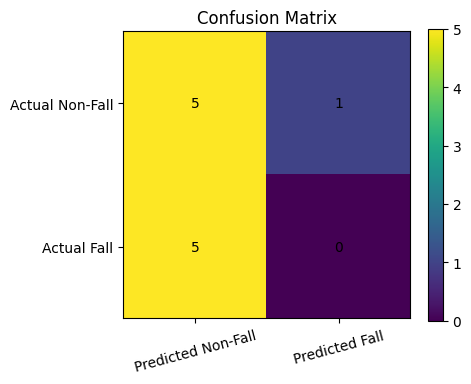

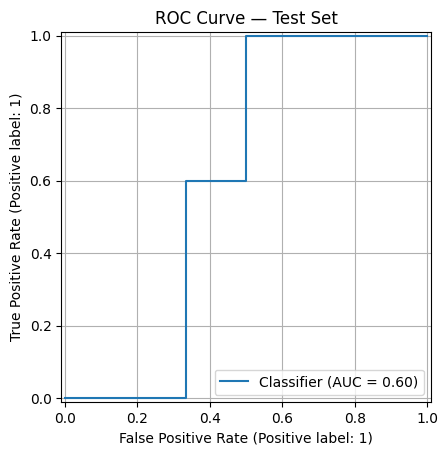

In [40]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_xticks([0, 1], labels=["Predicted Non-Fall", "Predicted Fall"], rotation=15)
ax.set_yticks([0, 1], labels=["Actual Non-Fall", "Actual Fall"])
ax.set_title("Confusion Matrix")
for (i, j), val in np.ndenumerate(cm):
    ax.text(j, i, str(val), ha="center", va="center")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

if len(np.unique(y_true)) == 2:
    RocCurveDisplay.from_predictions(y_true, y_prob)
    plt.title("ROC Curve — Test Set")
    plt.grid(True); plt.show()
else:
    print("ROC curve not available: test split contains only one class.")

In [3]:
import os
import json
from pathlib import Path
from getpass import getpass

kaggle_token = getpass("Paste your Kaggle API token here: ")

os.environ["KAGGLE_API_TOKEN"] = kaggle_token

print("Kaggle token added securely for this session!")

Paste your Kaggle API token here: ··········
Kaggle token added securely for this session!
